# CogniStream — Exploratory Data Analysis

## Objectives

1. Understand feature distributions.
2. Examine cognitive-load patterns.
3. Compare cognitive load between task-success groups.
4. Investigate associations between coding hours, distractions,
   sleep, caffeine, and AI usage.
5. Explore differences across descriptive feature categories.

## Important limitation

The dataset does not contain session timestamps or temporal sequences.
Therefore, this notebook does not claim to measure actual flow-state
duration or changes in cognitive load over time.

All associations are exploratory and do not establish causation.

In [ ]:
from pathlib import Path
import sys

current_dir = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        folder
        for folder in [current_dir, *current_dir.parents]
        if (folder / "src" / "schema.py").is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate the CogniStream project root."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt


from IPython.display import display

from src.features import (
    engineer_features,
    CLEANED_DATA_PATH,
    FEATURED_DATA_PATH,
)

print("Project root:", PROJECT_ROOT)
print("EDA notebook initialized.")

Project root: C:\PlayGround\Infotact Data Analytics\CogniStream
EDA notebook initialized.


In [18]:
if not CLEANED_DATA_PATH.exists():
    raise FileNotFoundError(
        "Cleaned dataset not found. Run "
        "'python -m src.cleaning' from the project root."
    )

cleaned_df = pd.read_csv(CLEANED_DATA_PATH)

featured_df = engineer_features(cleaned_df)

FEATURED_DATA_PATH.parent.mkdir(
    parents=True,
    exist_ok=True,
)

featured_df.to_csv(
    FEATURED_DATA_PATH,
    index=False,
)

print("Cleaned shape:", cleaned_df.shape)
print("Featured shape:", featured_df.shape)

display(featured_df.head())

Cleaned shape: (500, 9)
Featured shape: (500, 18)


,hours_coding,coffee_intake_mg,distractions,sleep_hours,commits,bugs_reported,ai_usage_hours,cognitive_load,task_success,coding_hours_band,sleep_band,cognitive_load_band,distraction_band,distractions_per_coding_hour,commits_per_coding_hour,bugs_per_commit,ai_hours_per_coding_hour,task_success_label
0,5.99,600.0,1.0,5.8,2.0,1.0,0.71,5.4,1.0,Moderate (>4-8h),Short (<6h),Moderate (>3-6),Low (0-2),0.166945,0.333890,0.500000,0.118531,Successful
1,4.72,568.0,2.0,6.9,5.0,3.0,1.75,4.7,1.0,Moderate (>4-8h),Medium (6-<8h),Moderate (>3-6),Low (0-2),0.423729,1.059322,0.600000,0.370763,Successful
2,6.30,560.0,1.0,8.9,2.0,0.0,2.27,2.2,1.0,Moderate (>4-8h),Long (>=8h),Low (<=3),Low (0-2),0.158730,0.317460,0.000000,0.360317,Successful
3,8.05,600.0,7.0,6.3,9.0,5.0,1.40,5.9,0.0,Long (>8h),Medium (6-<8h),Moderate (>3-6),High (6+),0.869565,1.118012,0.555556,0.173913,Unsuccessful
4,4.53,421.0,6.0,6.9,4.0,0.0,1.26,6.3,1.0,Moderate (>4-8h),Medium (6-<8h),High (>6),High (6+),1.324503,0.883002,0.000000,0.278146,Successful


In [19]:
numeric_columns = [
    "hours_coding",
    "coffee_intake_mg",
    "distractions",
    "sleep_hours",
    "commits",
    "bugs_reported",
    "ai_usage_hours",
    "cognitive_load",
    "task_success",
]

display(
    featured_df[numeric_columns].describe().T.round(2)
)

,count,mean,std,min,25%,50%,75%,max
hours_coding,500.0,5.02,1.95,0.0,3.60,5.03,6.28,12.00
coffee_intake_mg,500.0,463.19,142.33,6.0,369.50,500.50,600.00,600.00
distractions,500.0,2.98,1.68,0.0,2.00,3.00,4.00,8.00
sleep_hours,500.0,6.98,1.46,3.0,6.10,6.95,7.90,10.00
commits,500.0,4.61,2.70,0.0,3.00,5.00,6.00,13.00
bugs_reported,500.0,0.86,1.10,0.0,0.00,0.00,2.00,5.00
ai_usage_hours,500.0,1.51,1.09,0.0,0.70,1.26,2.07,6.36
cognitive_load,500.0,4.50,1.87,1.0,3.18,4.40,5.80,10.00
task_success,500.0,0.61,0.49,0.0,0.00,1.00,1.00,1.00


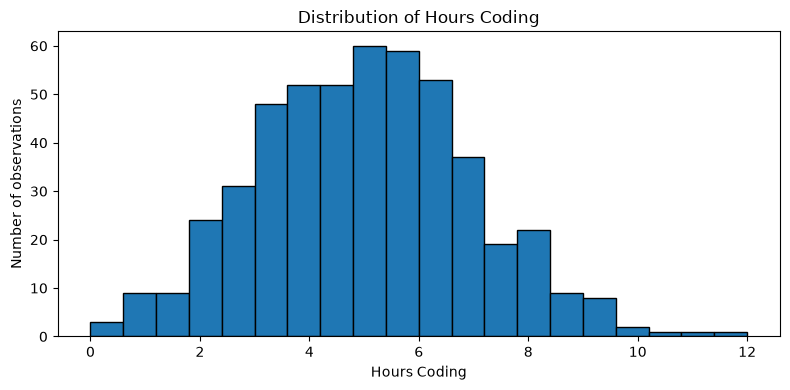

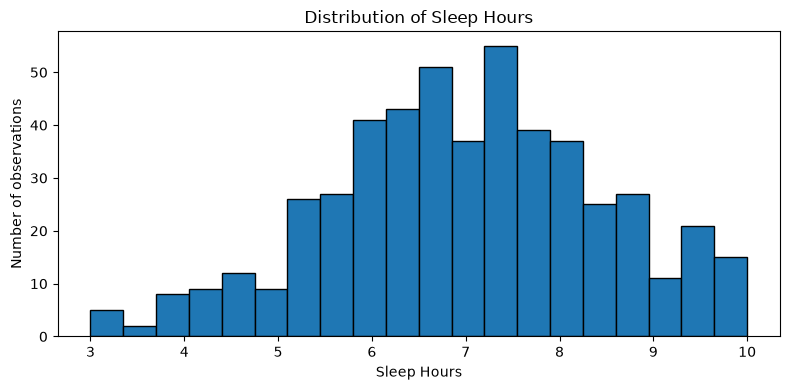

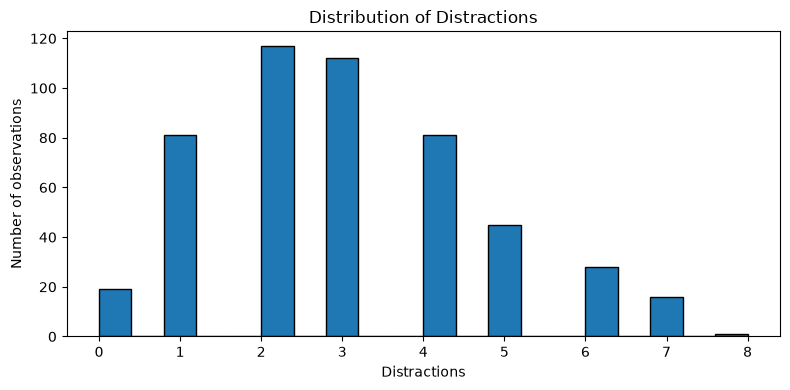

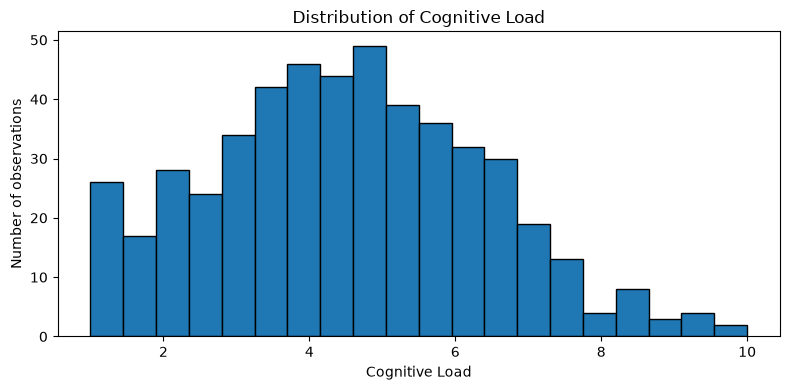

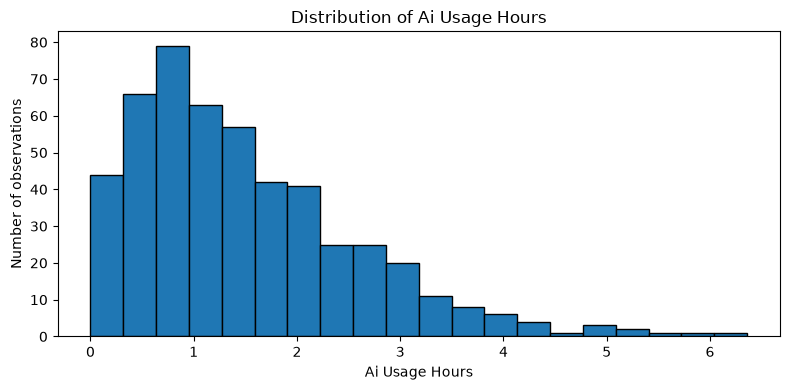

In [ ]:
variables = [
    "hours_coding",
    "sleep_hours",
    "distractions",
    "cognitive_load",
    "ai_usage_hours",
]

for column in variables:
    values = pd.to_numeric(
        featured_df[column],
        errors="coerce",
    ).dropna()

    fig, ax = plt.subplots(figsize=(8, 4))

    ax.hist(
        values,
        bins=20,
        edgecolor="black",
    )

    ax.set_title(
        f"Distribution of {column.replace('_', ' ').title()}"
    )
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Number of observations")

    fig.tight_layout()
    plt.show()

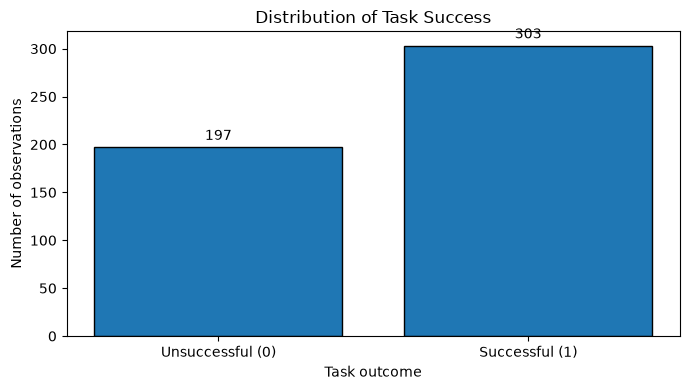

Task outcome counts:
task_success
0    197
1    303
Name: count, dtype: int64


In [22]:
success_counts = (
    featured_df["task_success"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

labels = ["Unsuccessful (0)", "Successful (1)"]

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    labels,
    success_counts.values,
    edgecolor="black",
)

ax.set_title("Distribution of Task Success")
ax.set_xlabel("Task outcome")
ax.set_ylabel("Number of observations")

ax.bar_label(bars, padding=3)

fig.tight_layout()
plt.show()

print("Task outcome counts:")
print(success_counts)

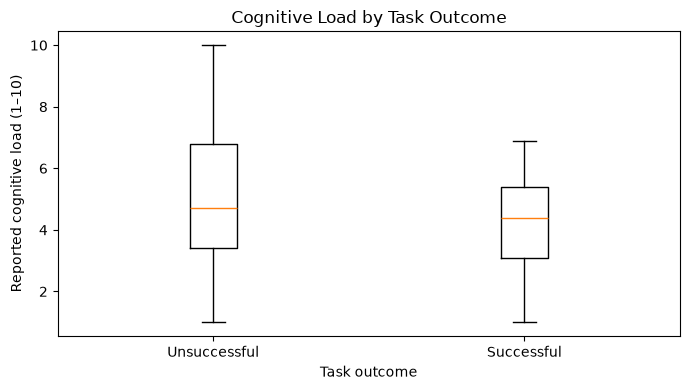

Cognitive load summary by outcome:


,count,mean,median,std
task_success,,,,
0.0,197,4.96,4.7,2.18
1.0,303,4.20,4.4,1.57


In [23]:
fig, ax = plt.subplots(figsize=(7, 4))

groups = [
    featured_df.loc[
        featured_df["task_success"] == outcome,
        "cognitive_load",
    ].dropna()
    for outcome in [0, 1]
]

ax.boxplot(
    groups,
    tick_labels=["Unsuccessful", "Successful"],
)

ax.set_title("Cognitive Load by Task Outcome")
ax.set_xlabel("Task outcome")
ax.set_ylabel("Reported cognitive load (1–10)")

fig.tight_layout()
plt.show()

print("Cognitive load summary by outcome:")

display(
    featured_df.groupby("task_success")["cognitive_load"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

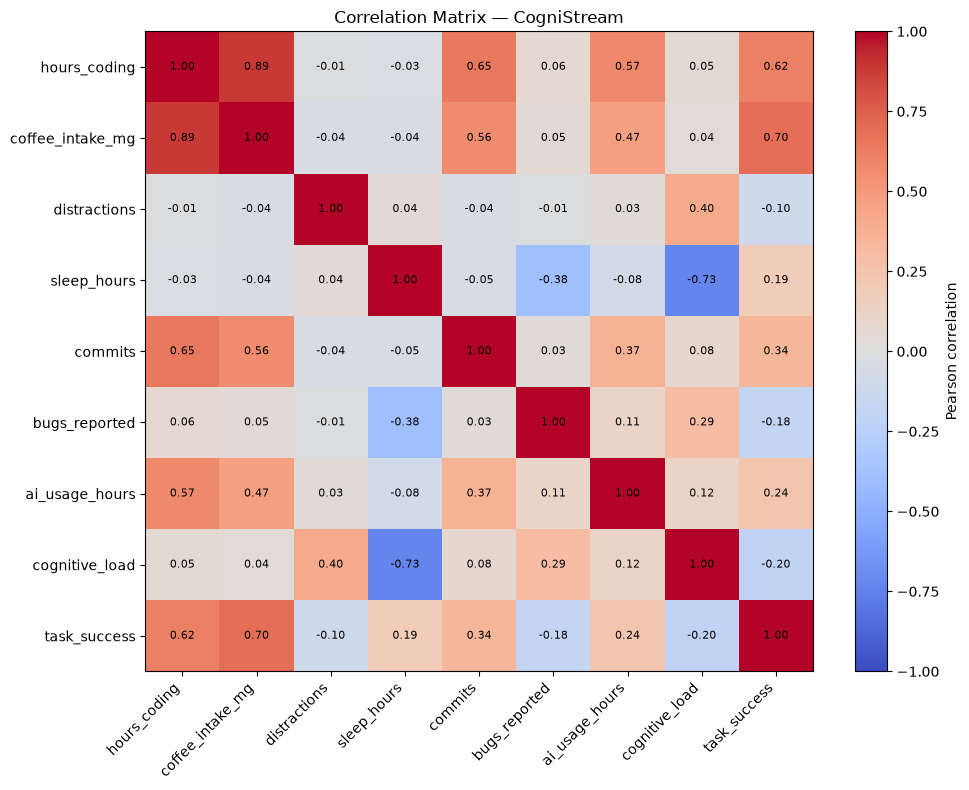

In [24]:
import numpy as np

numeric_columns = [
    "hours_coding",
    "coffee_intake_mg",
    "distractions",
    "sleep_hours",
    "commits",
    "bugs_reported",
    "ai_usage_hours",
    "cognitive_load",
    "task_success",
]

corr = featured_df[numeric_columns].corr()

fig, ax = plt.subplots(figsize=(10, 8))

image = ax.imshow(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto",
)

ax.set_xticks(range(len(numeric_columns)))
ax.set_yticks(range(len(numeric_columns)))

ax.set_xticklabels(
    numeric_columns,
    rotation=45,
    ha="right",
)

ax.set_yticklabels(numeric_columns)

for row in range(len(numeric_columns)):
    for col in range(len(numeric_columns)):
        ax.text(
            col,
            row,
            f"{corr.iloc[row, col]:.2f}",
            ha="center",
            va="center",
            fontsize=8,
        )

ax.set_title("Correlation Matrix — CogniStream")

fig.colorbar(image, ax=ax, label="Pearson correlation")
fig.tight_layout()
plt.show()

In [ ]:
fig = px.scatter(
    featured_df,
    x="hours_coding",
    y="cognitive_load",
    color="task_success_label",
    hover_data=[
        "distractions",
        "sleep_hours",
        "ai_usage_hours",
    ],
    title="Coding Hours vs Reported Cognitive Load",
    labels={
        "hours_coding": "Coding hours",
        "cognitive_load": "Reported cognitive load",
        "task_success_label": "Task outcome",
    },
)

fig.update_layout(
    template="plotly_white",
)

fig.show()

In [ ]:
correlation_columns = [
    "hours_coding",
    "coffee_intake_mg",
    "distractions",
    "sleep_hours",
    "commits",
    "bugs_reported",
    "ai_usage_hours",
    "cognitive_load",
    "task_success",
]

correlation_matrix = featured_df[
    correlation_columns
].corr(method="pearson")

display(correlation_matrix.round(2))

In [ ]:
fig = px.imshow(
    correlation_matrix,
    text_auto=".2f",
    aspect="auto",
    color_continuous_scale="RdBu",
    zmin=-1,
    zmax=1,
    title="Correlation Matrix — Developer Productivity",
)

fig.update_layout(
    template="plotly_white",
)

fig.show()

In [ ]:
fig = px.box(
    featured_df,
    x="sleep_band",
    y="cognitive_load",
    color="sleep_band",
    title="Reported Cognitive Load by Sleep Category",
    labels={
        "sleep_band": "Sleep category",
        "cognitive_load": "Reported cognitive load",
    },
)

fig.update_layout(
    template="plotly_white",
    showlegend=False,
)

fig.show()

In [ ]:
print("=" * 55)
print("COGNISTREAM — EDA CHECK")
print("=" * 55)

print("Rows:", len(featured_df))
print("Original features:", len(cleaned_df.columns))
print("Engineered features:", len(featured_df.columns))

print(
    "New derived columns:",
    [
        col
        for col in featured_df.columns
        if col not in cleaned_df.columns
    ],
)

print(
    "Unique task outcomes:",
    featured_df["task_success_label"].unique().tolist(),
)

assert len(featured_df) == len(cleaned_df)
assert featured_df["task_success"].isin([0, 1]).all()

print("\nFeature engineering and EDA checks passed.")

In [ ]:
import sys
import nbformat
import plotly
import plotly.io as pio

print("Python:", sys.executable)
print("nbformat version:", nbformat.__version__)
print("nbformat location:", nbformat.__file__)
print("Plotly version:", plotly.__version__)
print("Default renderer:", pio.renderers.default)

import plotly.express as px

fig = px.histogram(
    featured_df,
    x="cognitive_load",
    title="Cognitive Load Distribution",
)

fig.show(renderer="browser")